In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

In [ ]:
BATCH_SIZE = 128
MODEL_DIR = "checkpoints"
os.makedirs(MODEL_DIR, exist_ok=True)

In [ ]:
(x_train, y_train), (x_test, y_test) = (
  tf.keras.datasets.cifar10.load_data()
)

In [ ]:
CLASS_NAMES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

In [ ]:
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", x_test.shape)
print("Test labels:", y_test.shape)

Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Test images: (10000, 32, 32, 3)
Test labels: (10000, 1)


In [ ]:
x_val, y_val = x_train[-5000:], y_train[-5000:]
x_train, y_train = x_train[:-5000], y_train[:-5000]


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

In [ ]:
def prepare_dataset(images, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((images, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(images), seed=24,
            reshuffle_each_iteration=True
        )


    dataset = dataset.map(
        lambda image, label: (
            tf.cast(image, tf.float32) / 255.0,
            tf.cast(tf.squeeze(label), tf.int32)
        ),
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)
    return dataset

train_ds = prepare_dataset(x_train, y_train, training=True)
val_ds = prepare_dataset(x_val, y_val)
test_ds = prepare_dataset(x_test, y_test)


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# CIFAR-10 images are 32x32. Pre-trained models like EfficientNet expect larger images.
# We will add a resizing layer to scale images up to 128x128 for better feature extraction.

img_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomZoom(0.1)
], name="strong_augmentation")

def build_efficientnet_model():
    inputs = layers.Input(shape=(32, 32, 3))

    # Apply data augmentation
    x = img_augmentation(inputs)

    # Resize images to 128x128 to match EfficientNet resolution expectations
    x = layers.Resizing(128, 128)(x)

    # Load pre-trained EfficientNetB0 without top classifier
    base_model = tf.keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_tensor=x
    )

    # Freeze the base model weights initially (or keep them trainable with a small learning rate)
    base_model.trainable = True
    # Block 1
    x = layers.Conv2D(64, (3, 3), padding="same",
                  use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(64, (3, 3), padding="same",
                  use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.25)(x)

# Block 2
    x = layers.Conv2D(128, (3, 3), padding="same",
                  use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(128, (3, 3), padding="same",
                  use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.30)(x)

# Block 3
    x = layers.Conv2D(256, (3, 3), padding="same",
                  use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(0.35)(x)

    # Add a custom classification head
    x = layers.GlobalAveragePooling2D()(base_model.output)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(10, activation="softmax")(x)

    model = models.Model(inputs, outputs, name="EfficientNet_CIFAR10")
    return model

transfer_model = build_efficientnet_model()

# We compile the model with a very low learning rate since we are fine-tuning the entire model
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

transfer_model.summary()

Model: "EfficientNet_CIFAR10"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_8       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ strong_augmentation │ (None, 32, 32, 3) │          0 │ input_layer_8[0]… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resizing_2          │ (None, 128, 128,  │          0 │ strong_augmentat… │
│ (Resizing)          │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_4         │ (None, 128, 128,  │          0 │ resizing_2[0][0]  │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_2     │ (None, 128, 128,  │          7 │ rescaling_4[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_5         │ (None, 128, 128,  │          0 │ normalization_2[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 129, 129,  │          0 │ rescaling_5[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 64, 64,    │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 64, 64,    │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 64, 64,    │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 64, 64,    │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 64, 64,    │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 64, 64,    │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc

 Total params: 4,386,221 (16.73 MB)

 Trainable params: 4,341,126 (16.56 MB)

 Non-trainable params: 45,095 (176.16 KB)

In [ ]:
# Fine-tune the new EfficientNet model
transfer_callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "best_transfer_model.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    )
]

# Re-prepare dataset with float normalization but WITHOUT hand-coded resizing
# EfficientNet handles internal scaling, but we pass scaled inputs [0, 1]
history_transfer = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=transfer_callbacks
)

Epoch 1/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 459ms/step - accuracy: 0.2988 - loss: 2.3425
Epoch 1: val_accuracy improved from None to 0.09880, saving model to best_transfer_model.keras

Epoch 1: finished saving model to best_transfer_model.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 210s 483ms/step - accuracy: 0.4072 - loss: 1.8897 - val_accuracy: 0.0988 - val_loss: 2.6350 - learning_rate: 1.0000e-04
Epoch 2/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 449ms/step - accuracy: 0.6086 - loss: 1.1783
Epoch 2: val_accuracy improved from 0.09880 to 0.37500, saving model to best_transfer_model.keras

Epoch 2: finished saving model to best_transfer_model.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 163s 464ms/step - accuracy: 0.6393 - loss: 1.0772 - val_accuracy: 0.3750 - val_loss: 1.8237 - learning_rate: 1.0000e-04
Epoch 3/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 449ms/step - accuracy: 0.7132 - loss: 0.8393
Epoch 3: val_accuracy did not improve from 0.37500
352/352 ━━━━━━━━━━━━━━━━━━━━ 162s 460ms/step - accuracy: 0.7311 - loss: 

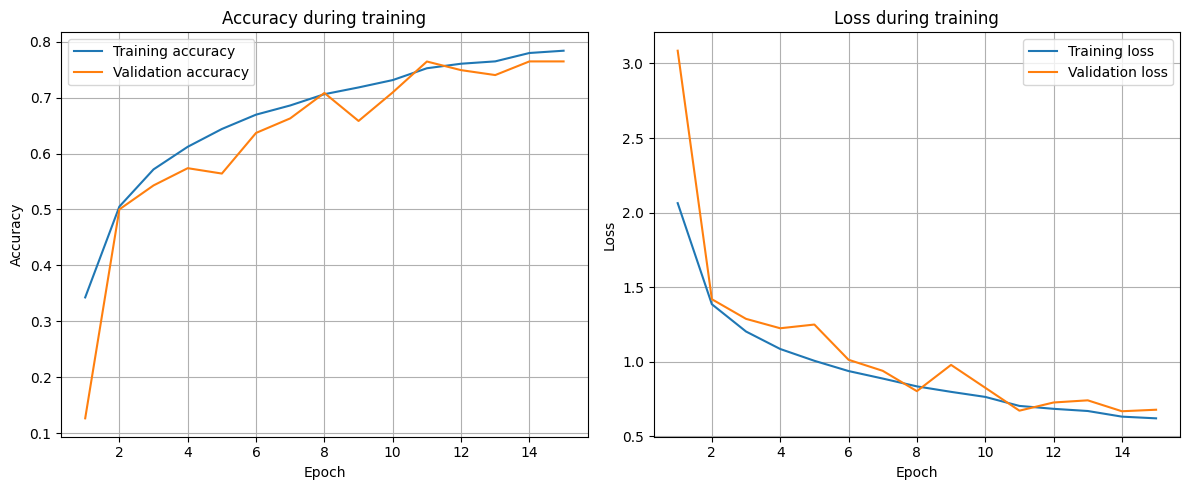

In [ ]:
epochs_ran = range(1, len(history.history["loss"]) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_ran, history.history["accuracy"], label="Training accuracy")
plt.plot(epochs_ran, history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy during training")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_ran, history.history["loss"], label="Training loss")
plt.plot(epochs_ran, history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss during training")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()


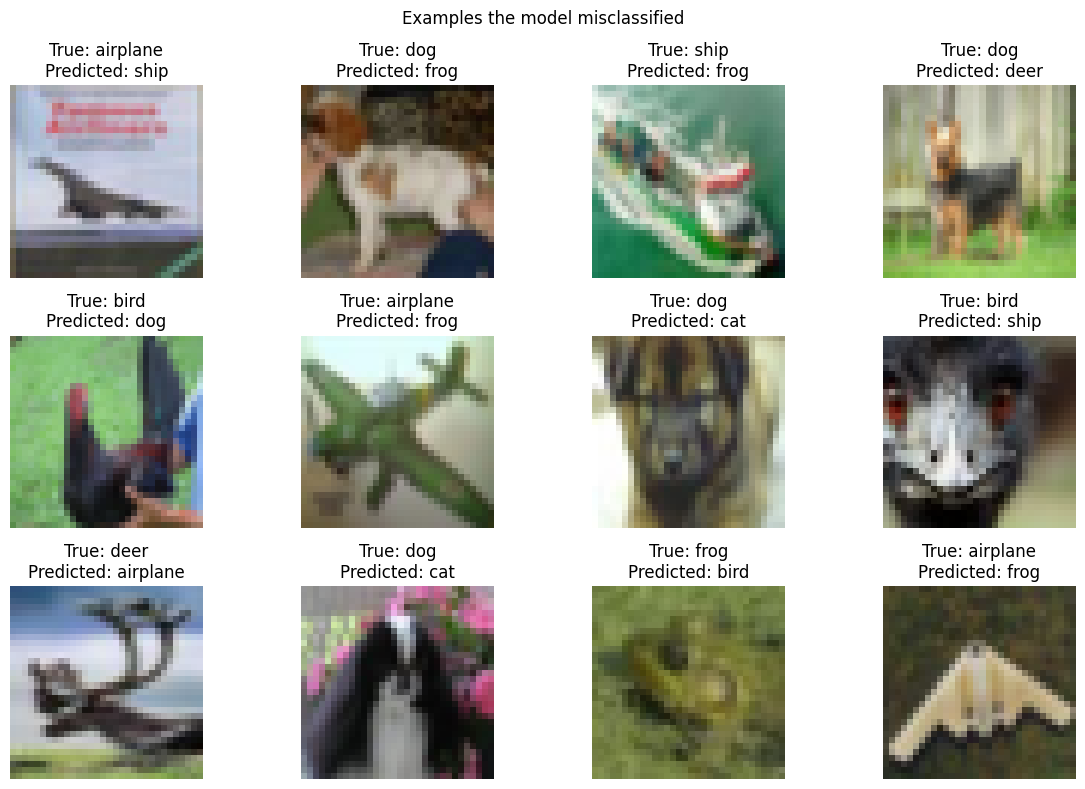

Done! Check training_curves.png and misclassified_images.png.


In [ ]:
wrong_images = []
wrong_true = []
wrong_pred = []

for images, labels in test_ds:
    probabilities = model.predict(images, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    labels_np = labels.numpy()

    wrong_indices = np.where(predictions != labels_np)[0]
    for index in wrong_indices:
        wrong_images.append(images[index].numpy())
        wrong_true.append(int(labels_np[index]))
        wrong_pred.append(int(predictions[index]))
        if len(wrong_images) >= 12:
            break

    if len(wrong_images) >= 12:
        break

if wrong_images:
    plt.figure(figsize=(12, 8))
    for i, image in enumerate(wrong_images):
        plt.subplot(3, 4, i + 1)
        plt.imshow(np.clip(image, 0, 1))
        plt.title(
            f"True: {CLASS_NAMES[wrong_true[i]]}\n"
            f"Predicted: {CLASS_NAMES[wrong_pred[i]]}"
        )
        plt.axis("off")

    plt.suptitle("Examples the model misclassified")
    plt.tight_layout()
    plt.savefig("misclassified_images.png", dpi=150)
    plt.show()
else:
    print("No misclassified images found in the inspected examples.")

print("Done! Check training_curves.png and misclassified_images.png.")


In [ ]:
import numpy as np
from sklearn.metrics import classification_report

# 1. Load the best saved model weights
try:
    print("Loading the best saved weights from checkpoint...")
    transfer_model.load_weights("best_transfer_model.keras")
    print("Successfully loaded best_transfer_model.keras!")
except Exception as e:
    print(f"Could not load checkpoint: {e}. Proceeding with current model weights.")

# 2. Evaluate on the test dataset
test_loss, test_accuracy = transfer_model.evaluate(test_ds, verbose=1)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# 3. Generate predictions and compare with ground truth
all_preds = []
all_labels = []

for images, labels in test_ds:
    preds = transfer_model.predict(images, verbose=0)
    all_preds.extend(np.argmax(preds, axis=1))
    all_labels.extend(labels.numpy())

print("\nDetailed Classification Report:")
print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES))

Loading the best saved weights from checkpoint...
Successfully loaded best_transfer_model.keras!
79/79 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - accuracy: 0.8943 - loss: 0.3121

Test Loss: 0.3121
Test Accuracy: 89.43%

Detailed Classification Report:
              precision    recall  f1-score   support

    airplane       0.89      0.93      0.91      1000
  automobile       0.88      0.98      0.93      1000
        bird       0.89      0.90      0.89      1000
         cat       0.73      0.88      0.80      1000
        deer       0.92      0.88      0.90      1000
         dog       0.90      0.78      0.84      1000
        frog       0.94      0.92      0.93      1000
       horse       0.94      0.89      0.92      1000
        ship       0.94      0.93      0.93      1000
       truck       0.97      0.85      0.91      1000

    accuracy                           0.89     10000
   macro avg       0.90      0.89      0.89     10000
weighted avg       0.90      0.89      0.89     10